# Analyzing NFL Data

Markdown cells were typed by Benjamin Robinson and enhanced by Codex.

**Data limitation:** Weekly Next Gen Stats receiving data covers only a subset of receivers and targets. In the 2024 regular-season coverage check, all included receivers were wide receivers or tight ends with at least five targets that week. The target-weighted separation average therefore represents the included receivers, and coverage varies between teams and games. This may bias comparisons of quarterback EPA per dropback. Results should be interpreted as associations within the available data, and cannot establish that greater separation causes improved quarterback performance.

In [65]:
import nflreadpy as nfl

SEASONS = list(range(2020, 2026))

receiving = nfl.load_nextgen_stats(
    seasons=SEASONS,
    stat_type="receiving",
).to_pandas()

receiving.head()

,season,season_type,week,player_display_name,player_position,team_abbr,avg_cushion,avg_separation,avg_intended_air_yards,percent_share_of_intended_air_yards,...,yards,rec_touchdowns,avg_yac,avg_expected_yac,avg_yac_above_expectation,player_gsis_id,player_first_name,player_last_name,player_jersey_number,player_short_name
0,2020,REG,0,Darnell Mooney,WR,CHI,7.627528,3.219063,11.735408,24.448923,...,631.0,4,4.420328,3.913009,0.507318,00-0036309,Darnell,Mooney,11,D.Mooney
1,2020,REG,0,Marquise Brown,WR,BAL,7.455670,3.265745,13.747900,39.296556,...,769.0,8,4.845345,3.876106,0.969239,00-0035662,Marquise,Brown,15,M.Brown
2,2020,REG,0,Braxton Berrios,WR,NYJ,7.141667,3.423246,7.708000,10.428849,...,394.0,3,6.172703,5.614924,0.557779,00-0034419,Braxton,Berrios,10,B.Berrios
3,2020,REG,0,Laviska Shenault,WR,JAX,7.064571,3.311376,6.410253,10.522958,...,600.0,5,5.222069,4.135107,1.086962,00-0036268,Laviska,Shenault,10,L.Shenault Jr.
4,2020,REG,0,Henry Ruggs,WR,LV,6.963590,3.347403,16.919535,16.758382,...,452.0,2,5.998077,5.830800,0.167277,00-0036357,Henry,Ruggs,11,H.Ruggs


In [66]:
receiving_weekly = receiving.loc[
    (receiving["season_type"] == "REG") & (receiving["week"] > 0)
].copy()

receiving_weekly.head()

,season,season_type,week,player_display_name,player_position,team_abbr,avg_cushion,avg_separation,avg_intended_air_yards,percent_share_of_intended_air_yards,...,yards,rec_touchdowns,avg_yac,avg_expected_yac,avg_yac_above_expectation,player_gsis_id,player_first_name,player_last_name,player_jersey_number,player_short_name
132,2020,REG,1,Curtis Samuel,WR,CAR,8.771667,3.172406,7.430000,21.024335,...,38.0,0,1.068000,2.811129,-1.743129,00-0033282,Curtis,Samuel,10,C.Samuel
133,2020,REG,1,Amari Cooper,WR,DAL,8.686429,2.408512,7.993571,42.671395,...,81.0,0,1.675000,2.228499,-0.553499,00-0031544,Amari,Cooper,19,A.Cooper
134,2020,REG,1,DeSean Jackson,WR,PHI,8.604286,2.955064,29.038571,40.384233,...,46.0,0,3.950000,3.576771,0.373229,00-0026189,DeSean,Jackson,10,D.Jackson
135,2020,REG,1,Henry Ruggs III,WR,LV,8.178000,4.694896,18.524000,60.484556,...,55.0,0,7.630000,8.236114,-0.606114,00-0036357,Henry,Ruggs,11,H.Ruggs
136,2020,REG,1,Darren Waller,TE,LV,8.081667,3.208908,3.361250,17.560243,...,45.0,0,5.728333,6.115772,-0.387439,00-0031610,Darren,Waller,83,D.Waller


I am investigating which quarterbacks show the largest increase in EPA per dropback in games where their receivers average more separation. This notebook combines the 2020 to 2025 regular seasons into one ranking per quarterback.

In [67]:
columns = ["season", "week", "team_abbr", "player_gsis_id", "targets", "avg_separation"]

print(receiving_weekly[columns].isna().sum())

print(
    "Duplicate receiver-week records:",
    receiving_weekly.duplicated(
        subset=["season", "week", "team_abbr", "player_gsis_id"],
    ).sum(),
)

season            0
week              0
team_abbr         0
player_gsis_id    0
targets           0
avg_separation    0
dtype: int64
Duplicate receiver-week records: 0


I checked the required columns for missing values and checked for duplicate receiver records within each team, season, and week. Both checks returned zero, so these checks identified no records requiring removal.

In [68]:
receiving_weekly["weighted_separation"] = (
    receiving_weekly["avg_separation"] * receiving_weekly["targets"]
)

team_separation = receiving_weekly.groupby(
    ["season", "week", "team_abbr"],
    as_index=False,
).agg(
    weighted_separation=("weighted_separation", "sum"),
    tracked_targets=("targets", "sum"),
)

team_separation["avg_separation"] = team_separation["weighted_separation"] / team_separation[
    "tracked_targets"
].where(
    team_separation["tracked_targets"] > 0,
)

team_separation.head()

,season,week,team_abbr,weighted_separation,tracked_targets,avg_separation
0,2020,1,ARI,98.368779,26,3.783415
1,2020,1,ATL,115.103565,41,2.807404
2,2020,1,BAL,42.570737,12,3.547561
3,2020,1,BUF,85.827167,26,3.301045
4,2020,1,CAR,73.792297,25,2.951692


I weighted each receiver’s average separation by their number of targets so receivers with more targets contribute more to the team average. I multiplied `avg_separation` by `targets`, summed those products for each team and week, and divided by the total targets.

In [69]:
pbp = nfl.load_pbp(SEASONS).to_pandas()

pbp[
    [
        "season",
        "week",
        "season_type",
        "posteam",
        "passer_player_id",
        "passer_player_name",
        "qb_dropback",
        "qb_scramble",
        "epa",
    ]
].head()

,season,week,season_type,posteam,passer_player_id,passer_player_name,qb_dropback,qb_scramble,epa
0,2020,1,REG,NaN,NaN,NaN,NaN,0.0,0.000000
1,2020,1,REG,SF,NaN,NaN,0.0,0.0,0.000000
2,2020,1,REG,SF,00-0031345,J.Garoppolo,1.0,0.0,1.294838
3,2020,1,REG,SF,NaN,NaN,0.0,0.0,0.857214
4,2020,1,REG,SF,NaN,NaN,0.0,0.0,-0.454665


In [70]:
dropbacks = pbp.loc[
    (pbp["season_type"] == "REG") & (pbp["qb_dropback"] == 1) & pbp["epa"].notna()
].copy()

dropbacks[["passer_player_name", "qb_scramble", "sack", "epa"]].head(10)

print("Total dropbacks:", len(dropbacks))
print(
    "Dropbacks missing passer ID:",
    dropbacks["passer_player_id"].isna().sum(),
)

dropbacks.groupby(["qb_scramble", "sack"]).agg(
    plays=("epa", "size"),
    missing_passer_id=("passer_player_id", lambda ids: ids.isna().sum()),
)

Total dropbacks: 122044
Dropbacks missing passer ID: 5864


plays  missing_passer_id
qb_scramble sack                           
0.0         0.0   108493                  0
            1.0     7686                  0
1.0         0.0     5864               5864
            1.0        1                  0

I found that 5,864 of the 122,044 regular-season dropbacks with an available EPA value were missing a passer ID. All missing passer IDs occurred on plays marked as scrambles. The breakdown also includes one play marked as both a scramble and a sack, which already had a passer ID.

In [71]:
dropbacks["qb_id"] = dropbacks["passer_player_id"].where(
    dropbacks["qb_scramble"] != 1,
    dropbacks["rusher_player_id"],
)

dropbacks["qb_name"] = dropbacks["passer_player_name"].where(
    dropbacks["qb_scramble"] != 1,
    dropbacks["rusher_player_name"],
)

print("Missing quarterback IDs:", dropbacks["qb_id"].isna().sum())
print("Missing quarterback names:", dropbacks["qb_name"].isna().sum())

Missing quarterback IDs: 1
Missing quarterback names: 1


I used `.where(condition, replacement)` to create consistent quarterback ID and name columns. This method keeps the original value when the condition is true and uses the replacement when it is false.

For plays where `qb_scramble != 1`, I kept `passer_player_id` and `passer_player_name`. For scrambles, I used `rusher_player_id` and `rusher_player_name` to identify the quarterback carrying the ball.

The saved checks show one missing quarterback ID and one missing quarterback name after this step. The remaining record needs investigation. Grouping by `qb_id` excludes rows with a missing ID by default, so that record is omitted from the game-level calculations.

In [72]:
qb_games = dropbacks.groupby(
    ["season", "week", "game_id", "posteam", "qb_id"],
    as_index=False,
).agg(
    qb_name=("qb_name", "first"),
    dropbacks=("epa", "size"),
    epa_per_dropback=("epa", "mean"),
)

qb_games.head()

,season,week,game_id,posteam,qb_id,qb_name,dropbacks,epa_per_dropback
0,2020,1,2020_01_ARI_SF,ARI,00-0035228,K.Murray,49,0.149354
1,2020,1,2020_01_ARI_SF,SF,00-0031345,J.Garoppolo,37,0.022257
2,2020,1,2020_01_CHI_DET,CHI,00-0033869,M.Trubisky,39,0.123672
3,2020,1,2020_01_CHI_DET,DET,00-0026498,M.Stafford,46,0.042396
4,2020,1,2020_01_CLE_BAL,BAL,00-0029665,R.Griffin,1,-0.906518


I grouped the dropbacks by season, week, game, team, and quarterback ID to create one row per quarterback per game. `"size"` counts dropbacks with an available EPA value, and `"mean"` calculates their average EPA.

In [73]:
qb_games = qb_games.merge(
    team_separation[["season", "week", "team_abbr", "avg_separation", "tracked_targets"]],
    left_on=["season", "week", "posteam"],
    right_on=["season", "week", "team_abbr"],
    how="left",
    validate="many_to_one",
)

qb_games[["qb_name", "week", "posteam", "dropbacks", "epa_per_dropback", "avg_separation"]].head()

,qb_name,week,posteam,dropbacks,epa_per_dropback,avg_separation
0,K.Murray,1,ARI,49,0.149354,3.783415
1,J.Garoppolo,1,SF,37,0.022257,2.449571
2,M.Trubisky,1,CHI,39,0.123672,1.503012
3,M.Stafford,1,DET,46,0.042396,2.162589
4,R.Griffin,1,BAL,1,-0.906518,3.547561


I matched each quarterback-game to team receiver separation using season, week, and team. `how="left"` keeps every quarterback-game, including those with missing separation data. `validate="many_to_one"` checks that each match has at most one team separation record. Quarterbacks who played for the same team in the same game receive the same separation average.

In [74]:
DROPBACKS_THRESHOLD = 20

analysis_games = qb_games.loc[
    (qb_games["dropbacks"] >= DROPBACKS_THRESHOLD) & qb_games["avg_separation"].notna()
].copy()

print("Quarterback-games before filtering:", len(qb_games))
print("Quarterback-games kept:", len(analysis_games))

analysis_games.groupby("qb_id").agg(
    qb_name=("qb_name", "first"),
    games=("game_id", "nunique"),
).sort_values("games", ascending=False)

Quarterback-games before filtering: 4055
Quarterback-games kept: 3022


,qb_name,games
qb_id,,
00-0034857,J.Allen,95
00-0033873,P.Mahomes,94
00-0036355,J.Herbert,94
00-0034855,B.Mayfield,88
00-0033106,J.Goff,81
...,...,...
00-0036384,B.DiNucci,1
00-0035146,T.McSorley,1
00-0038998,J.Haener,1


I required at least 20 dropbacks per game and an available separation average. These filters reduced the dataset from 4,055 to 3,022 quarterback-games. The table shows how many qualifying games each quarterback has before applying the minimum-game requirement.

In [75]:
MIN_GAMES = 10

games_per_qb = analysis_games.groupby("qb_id")["game_id"].nunique()

eligible_qbs = games_per_qb.loc[games_per_qb >= MIN_GAMES].index

analysis_games = analysis_games.loc[analysis_games["qb_id"].isin(eligible_qbs)].copy()

print("Quarterbacks included:", analysis_games["qb_id"].nunique())
print("Quarterback-games included:", len(analysis_games))

Quarterbacks included: 74
Quarterback-games included: 2829


I then required at least 10 qualifying games across the combined 2020 to 2025 period. `eligible_qbs` contains the IDs meeting this requirement, and `.isin(eligible_qbs)` keeps their records. This left 74 quarterbacks and 2,829 qualifying quarterback-games.

In [76]:
from statistics import linear_regression

import pandas as pd

MIN_SEPARATION_VALUES = 2

results = []

for qb_id, games in analysis_games.groupby("qb_id"):
    if games["avg_separation"].nunique() < MIN_SEPARATION_VALUES:
        continue

    slope, intercept = linear_regression(
        games["avg_separation"],
        games["epa_per_dropback"],
    )

    results.append(
        {
            "qb_id": qb_id,
            "qb_name": games["qb_name"].iloc[0],
            "games": len(games),
            "epa_change_per_yard": slope,
        },
    )

qb_separation_rankings = pd.DataFrame(results).sort_values(
    "epa_change_per_yard",
    ascending=False,
)

qb_separation_rankings

,qb_id,qb_name,games,epa_change_per_yard
1,00-0020531,D.Brees,11,0.357709
12,00-0029567,N.Foles,10,0.310939
8,00-0027939,C.Newton,16,0.297262
20,00-0031503,J.Winston,18,0.256861
14,00-0029701,R.Tannehill,49,0.250875
...,...,...,...,...
72,00-0040691,J.Dart,11,-0.095574
69,00-0039917,M.Penix,11,-0.144724
28,00-0033319,N.Mullens,14,-0.172097
9,00-0027973,A.Dalton,33,-0.248011


## Estimating the relationship

I fit a separate regression line for each quarterback across the combined 2020 to 2025 regular seasons, using receiver separation as the explanatory variable and EPA per dropback as the response variable. Each qualifying game receives equal weight. I require at least two distinct separation values so a slope can be calculated.

The slope estimates the change in EPA per dropback associated with one additional yard of separation. Pooling seasons can also reflect changes in teams, coaching, opponents, and quarterback performance over time. Confidence intervals have yet to be calculated.

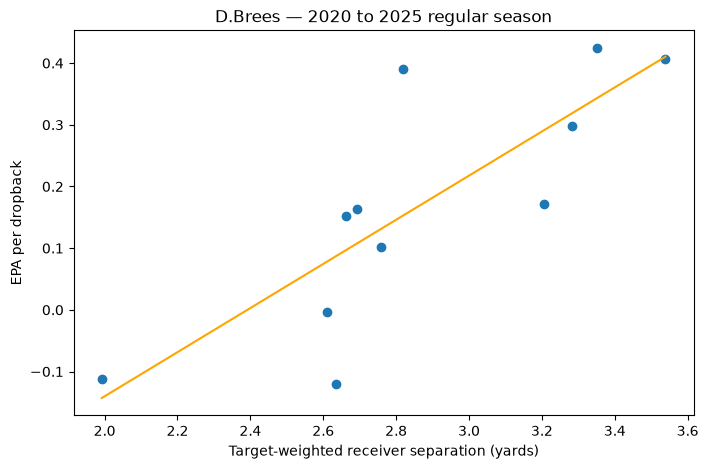

In [77]:
import matplotlib.pyplot as plt

top_qb = qb_separation_rankings.iloc[0]

games = analysis_games.loc[analysis_games["qb_id"] == top_qb["qb_id"]]

slope, intercept = linear_regression(
    games["avg_separation"],
    games["epa_per_dropback"],
)

x = games["avg_separation"].sort_values()
predicted_epa = intercept + slope * x

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(games["avg_separation"], games["epa_per_dropback"])
ax.plot(x, predicted_epa, color="orange")

ax.set_xlabel("Target-weighted receiver separation (yards)")
ax.set_ylabel("EPA per dropback")
ax.set_title(f"{top_qb['qb_name']} — 2020 to 2025 regular season")

plt.show()

## Examining the highest-ranked quarterback

The saved ranking places Drew Brees first, with an estimated slope of approximately 0.358 across 11 qualifying games. Each point represents one of his qualifying games. The horizontal axis shows target-weighted team receiver separation, and the vertical axis shows EPA per dropback. The orange line shows the fitted relationship, calculated as `intercept + slope * separation`.

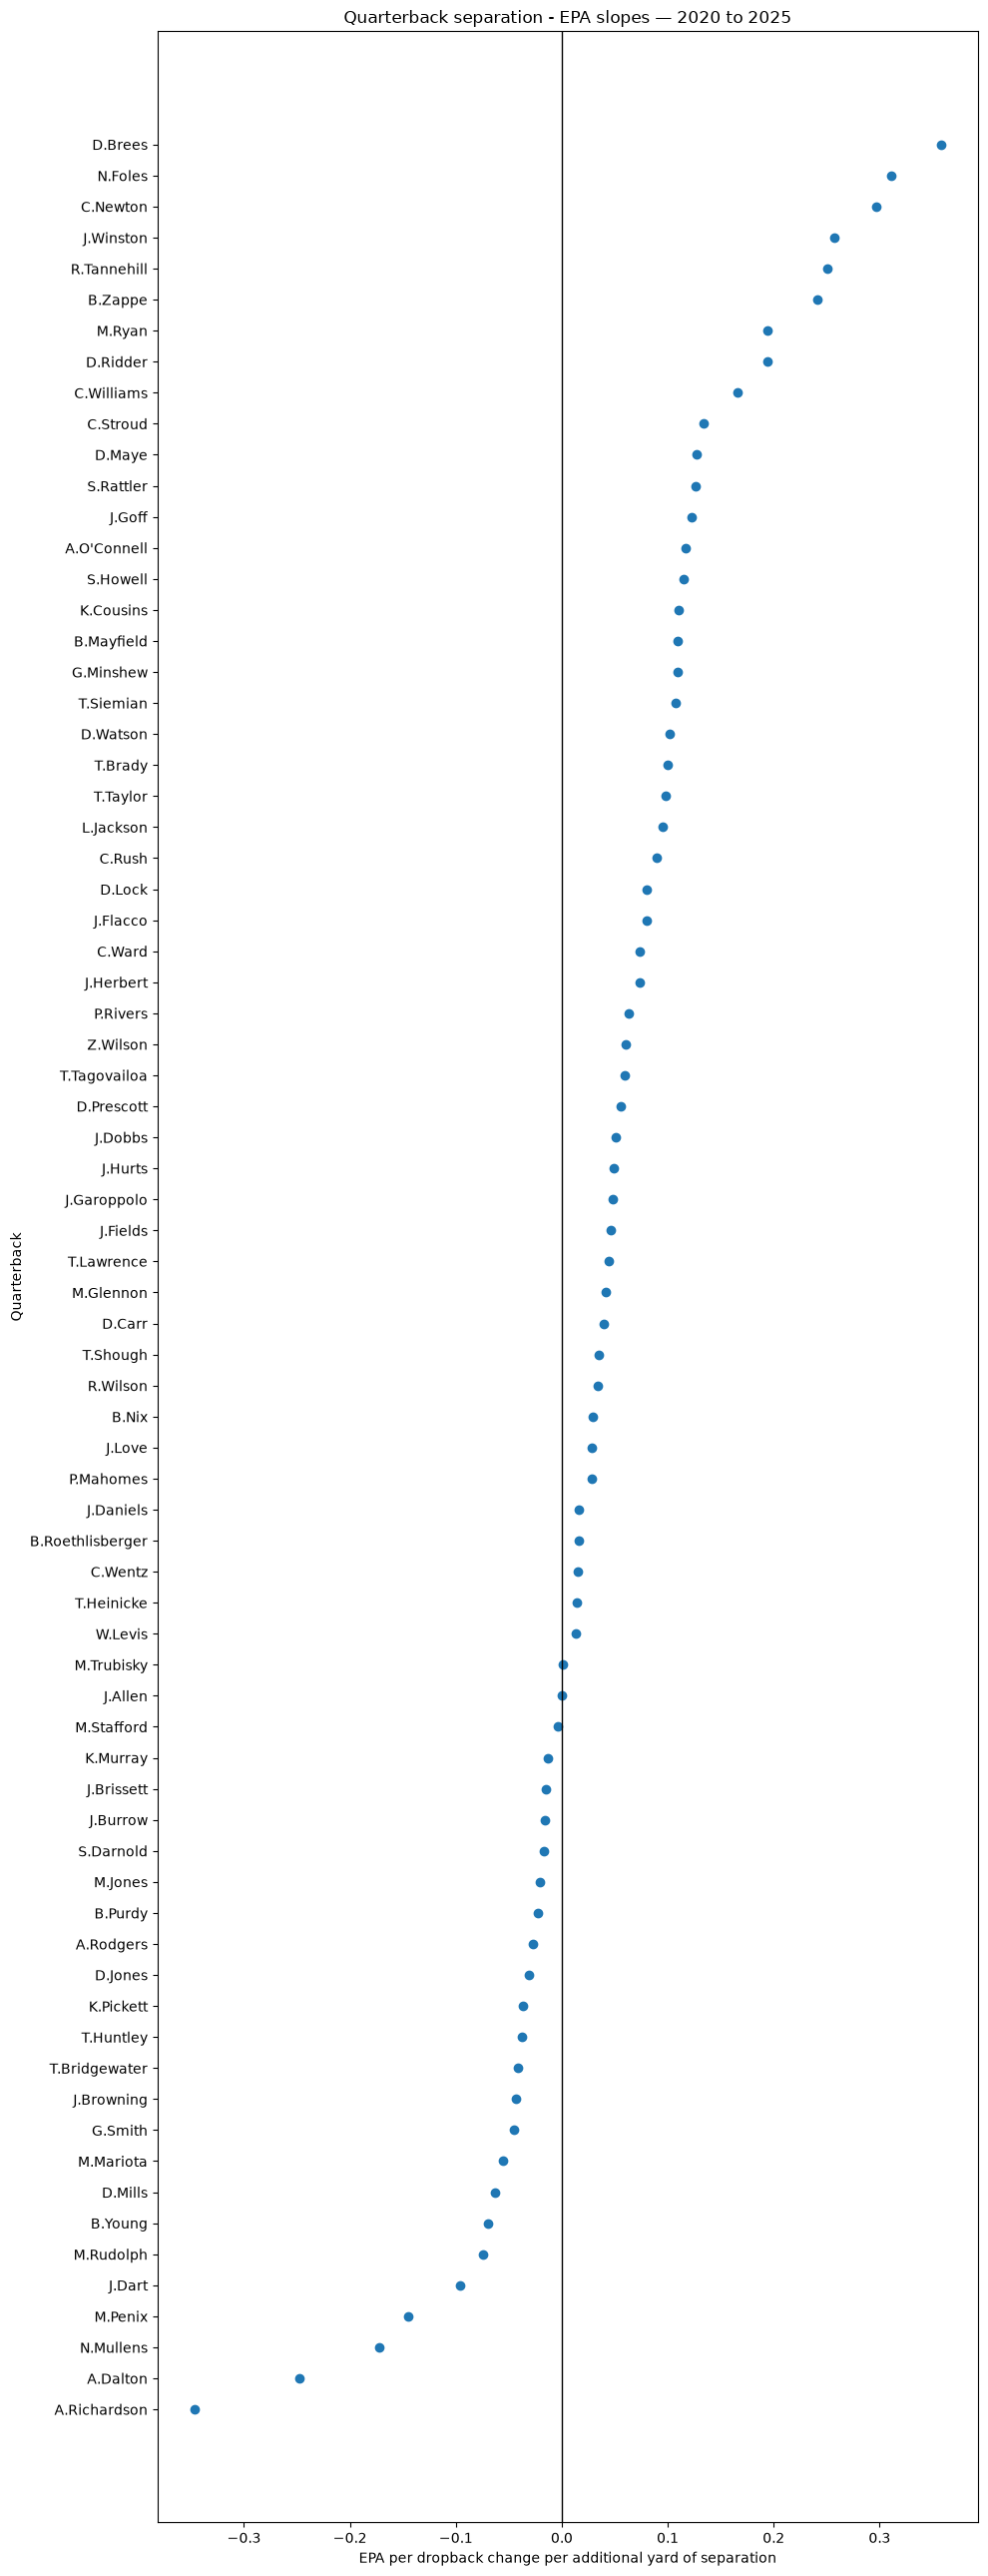

In [78]:
import matplotlib.pyplot as plt

rankings = qb_separation_rankings.sort_values("epa_change_per_yard")

fig, ax = plt.subplots(figsize=(10, max(6, len(rankings) * 0.35)))

ax.scatter(rankings["epa_change_per_yard"], rankings["qb_name"])
ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("EPA per dropback change per additional yard of separation")
ax.set_ylabel("Quarterback")
ax.set_title("Quarterback separation - EPA slopes — 2020 to 2025")

fig.tight_layout()
plt.show()

## Comparing quarterback slopes

This dot plot compares the slopes for all qualifying quarterbacks across 2020 to 2025. Points to the right of zero indicate a positive association between separation and EPA per dropback. Points to the left indicate a negative association. The ranking reflects estimated slopes, with uncertainty still to be assessed.

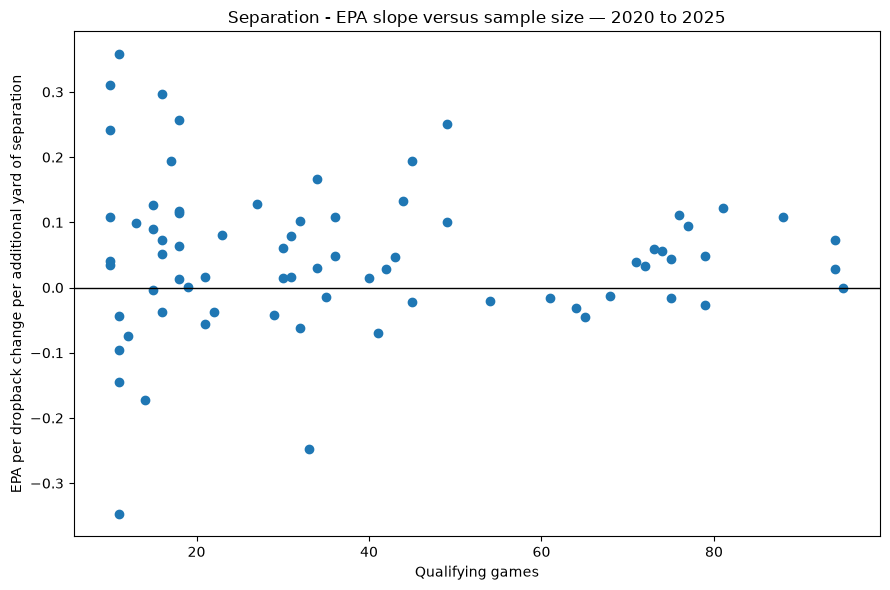

In [79]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    qb_separation_rankings["games"],
    qb_separation_rankings["epa_change_per_yard"],
)

ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Qualifying games")
ax.set_ylabel("EPA per dropback change per additional yard of separation")
ax.set_title("Separation - EPA slope versus sample size — 2020 to 2025")

fig.tight_layout()
plt.show()

## Comparing slopes and sample sizes

Each point represents one quarterback. The horizontal axis shows the number of qualifying games, and the vertical axis shows the estimated separation–EPA slope. This plot shows how much game data supports each estimate. Game count alone does not establish precision.

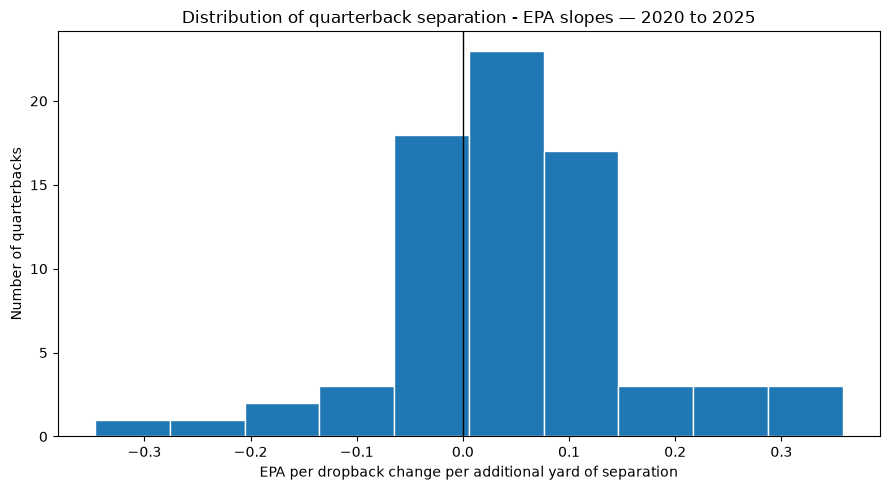

In [80]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    qb_separation_rankings["epa_change_per_yard"],
    bins=10,
    edgecolor="white",
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("EPA per dropback change per additional yard of separation")
ax.set_ylabel("Number of quarterbacks")
ax.set_title("Distribution of quarterback separation - EPA slopes — 2020 to 2025")

fig.tight_layout()
plt.show()

## Viewing the distribution of slopes

This histogram groups the slope estimates into 10 intervals. Each bar shows how many quarterbacks fall within that interval, and the vertical line marks zero. It summarizes the spread of positive and negative associations across the qualifying quarterbacks.

# Takeaway

Drew Brees, Nick Foles, and Cam Newton had the largest positive estimated slopes in the combined 2020 to 2025 analysis. Their slopes were approximately 0.358, 0.311, and 0.297 EPA per dropback per additional yard of receiver separation, based on 11, 10, and 16 qualifying games, respectively.

These results describe associations within the available receiver data. The leading estimates are based on relatively few games, and confidence intervals have yet to be calculated. Incomplete receiver coverage, changes across seasons, and one unresolved quarterback identity also limit interpretation.